# kNN: Position Decoding

Predicts sequence position (1–5) of InSeq odor trials with k-nearest neighbors (kNN), and compares two inputs:

- **Raw LFP:** the preprocessed 500 ms LFP windows
- **Latent LFP:** the CEBRA latents of the same trials

kNN labels a trial by the positions of the most similar training trials. Unlike logistic regression it learns no weights, so it shows whether trials of the same position simply sit close together.

Data, splits and features are the same as in `logistic_regression.ipynb`, so the two models can be compared directly.
One model per rat. The number of neighbors is chosen on the validation split, and the test split is used only for the final scores.
Scores are balanced accuracy; chance is 20% for five positions.

**Input:** `data/processed/raw_lfp/` and `data/processed/cebra_latents/`

## Setup

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams['figure.dpi'] = 110

## Paths

In [2]:
# Repository root: the first folder above this notebook that contains pyproject.toml
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())

RAW_ROOT    = REPO / 'data' / 'processed' / 'raw_lfp'
LATENT_ROOT = REPO / 'data' / 'processed' / 'cebra_latents'

SESSIONS = sorted(p.name for p in LATENT_ROOT.iterdir() if (p / 'cebra_latents.npz').is_file())
print('Rats:', SESSIONS)

Rats: ['080718_mitt', '081106_barat', '090212_stella', '090212_superchris', '090420_buchanan']


## Load data

Raw LFP and latents for each rat, with position labels and the train / validation / test split.

In [3]:
def load_session(session):
    """Raw LFP, CEBRA latents and position labels for one rat, checked to be in the same trial order."""
    with np.load(RAW_ROOT / session / 'position_decoding.npz') as raw, \
         np.load(LATENT_ROOT / session / 'cebra_latents.npz') as lat:
        assert np.array_equal(raw['trial_ids'], lat['trial_ids']), f'{session}: trial order differs'
        assert np.array_equal(raw['split'], lat['split']), f'{session}: splits differ'
        return dict(raw=raw['X'], latent=lat['Z'], y=raw['y'],
                    split=raw['split'].astype(str), trial_ids=raw['trial_ids'])


data = {session: load_session(session) for session in SESSIONS}
print({s: (d['raw'].shape, d['latent'].shape) for s, d in data.items()})

{'080718_mitt': ((249, 500, 22), (249, 500, 8)), '081106_barat': ((154, 500, 22), (154, 500, 8)), '090212_stella': ((190, 500, 21), (190, 500, 8)), '090212_superchris': ((187, 500, 21), (187, 500, 8)), '090420_buchanan': ((208, 500, 20), (208, 500, 8))}


## Features

Each trial is averaged into 50 ms time bins, the same way for raw LFP and latents, then flattened into one feature vector:
- **Raw:** 10 bins × channels
- **Latent:** 10 bins × 8 latent dimensions

**Why the same features as logistic regression:** any difference between the two notebooks then comes from the model, not from the inputs.
**Why 50 ms bins:** using every sample would give 11,000 raw features. kNN compares trials by distance, and with that many features almost every trial looks equally far from every other. Ten 50 ms bins keep the timing with about 200 features.

In [4]:
BIN_MS = 50   # width of each time bin (samples are 1 ms)


def bin_features(A, bin_ms=BIN_MS):
    """trials x samples x channels -> trials x (bins * channels), averaging within each time bin."""
    trials, samples, channels = A.shape
    assert samples % bin_ms == 0, f'{samples} samples do not split into {bin_ms} ms bins'
    binned = A.reshape(trials, samples // bin_ms, bin_ms, channels).mean(axis=2)
    return binned.reshape(trials, -1)


features = {session: {'raw': bin_features(d['raw']), 'latent': bin_features(d['latent'])}
            for session, d in data.items()}
display(pd.DataFrame({s: {name: f.shape for name, f in fs.items()} for s, fs in features.items()}).T)

,raw,latent
080718_mitt,"(249, 220)","(249, 80)"
081106_barat,"(154, 220)","(154, 80)"
090212_stella,"(190, 210)","(190, 80)"
090212_superchris,"(187, 210)","(187, 80)"
090420_buchanan,"(208, 200)","(208, 80)"


## Fit models

For each rat and each input, kNN is fitted on the training trials for each number of neighbors `k` and each weighting.
The combination with the best validation balanced accuracy is kept.

- **Why `k` from 1 to 25:** small `k` follows individual training trials closely (and their noise); large `k` averages over many neighbors. With 111–174 training trials per rat, 25 is about the largest `k` that still leaves room for each position's neighbors.
- **Why ties go to the larger `k`:** a vote over more neighbors is less likely to be fitting noise.
- **Why two weightings:** `uniform` gives every neighbor one vote; `distance` lets closer neighbors count more. The validation split picks one.
- **Why standardize features:** kNN compares trials by distance, so a feature with a larger scale would dominate. The scaler is fitted on training trials only.
- **Class imbalance:** kNN has no class weighting, so with large `k` it leans toward position 1, which has the most training trials. Balanced accuracy still scores every position equally.

In [5]:
import warnings
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import balanced_accuracy_score

warnings.filterwarnings('ignore', message='y_pred contains classes not in y_true')

K_GRID = [25, 15, 9, 5, 3, 1]          # largest first, so ties go to the smoother model
WEIGHTS = ['uniform', 'distance']      # every neighbor counts equally, or closer neighbors count more


def make_model(k, weights):
    """Scaler fitted on training trials, then kNN with Euclidean distance."""
    return make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k, weights=weights))


def fit_with_validation(F, y, split):
    """Fit one model per (k, weights) on train, keep the best validation balanced accuracy.

    Ties go to the larger k. The test split is not touched here.
    """
    train, val = split == 'train', split == 'validation'
    best = None
    for k in K_GRID:
        for weights in WEIGHTS:
            model = make_model(k, weights).fit(F[train], y[train])
            score = balanced_accuracy_score(y[val], model.predict(F[val]))
            if best is None or score > best['val_score']:
                best = dict(k=k, weights=weights, val_score=score, model=model)
    return best


fits, rows = {}, []
for session, d in data.items():
    for name in ('raw', 'latent'):
        best = fit_with_validation(features[session][name], d['y'], d['split'])
        fits[session, name] = best
        rows.append(dict(rat=session, input=name, k=best['k'], weights=best['weights'],
                         validation_bal_acc=round(best['val_score'], 3)))

display(pd.DataFrame(rows).set_index(['rat', 'input']))

k   weights  validation_bal_acc
rat               input                                   
080718_mitt       raw     25   uniform               0.333
                  latent  25  distance               0.260
081106_barat      raw      3   uniform               0.286
                  latent   9   uniform               0.362
090212_stella     raw      5  distance               0.468
                  latent   5  distance               0.347
090212_superchris raw     25   uniform               0.297
                  latent   5  distance               0.501
090420_buchanan   raw      3  distance               0.477
                  latent  15  distance               0.487

## Test results

Each chosen model is scored once on the test split. For comparison, the same model is refitted 50 times on shuffled training labels; a real score should sit above the 95th percentile of those shuffled scores.

**Why a shuffled baseline as well as 20% chance:** with test sets of 12–35 trials, a model with no real information can still score 30–50% by luck.
The shuffled scores show how high luck alone reaches for each rat.

In [6]:
N_SHUFFLES = 50
rng = np.random.default_rng(0)

results = []
for session, d in data.items():
    train, test = d['split'] == 'train', d['split'] == 'test'
    y = d['y']
    for name in ('raw', 'latent'):
        F, fit = features[session][name], fits[session, name]
        pred = fit['model'].predict(F[test])
        # Same k and weighting, refitted on shuffled training labels: the score a model gets by chance
        shuffled = [balanced_accuracy_score(y[test], make_model(fit['k'], fit['weights'])
                                            .fit(F[train], rng.permutation(y[train])).predict(F[test]))
                    for _ in range(N_SHUFFLES)]
        results.append(dict(rat=session, input=name, test_trials=int(test.sum()), k=fit['k'], weights=fit['weights'],
                            test_bal_acc=balanced_accuracy_score(y[test], pred),
                            shuffle_mean=np.mean(shuffled), shuffle_95th=np.percentile(shuffled, 95),
                            pred=pred))

results_df = pd.DataFrame(results).drop(columns='pred')
display(results_df.round(3))
display(results_df.pivot(index='rat', columns='input', values='test_bal_acc').agg(['mean', 'std']).round(3))

,rat,input,test_trials,k,weights,test_bal_acc,shuffle_mean,shuffle_95th
0,080718_mitt,raw,35,25,uniform,0.290,0.210,0.330
1,080718_mitt,latent,35,25,distance,0.136,0.183,0.294
2,081106_barat,raw,19,3,uniform,0.400,0.200,0.346
3,081106_barat,latent,19,9,uniform,0.317,0.209,0.371
4,090212_stella,raw,12,5,distance,0.300,0.185,0.350
5,090212_stella,latent,12,5,distance,0.350,0.209,0.450
6,090212_superchris,raw,18,25,uniform,0.200,0.208,0.333
7,090212_superchris,latent,18,5,distance,0.250,0.207,0.345
8,090420_buchanan,raw,15,3,distance,0.400,0.203,0.385
9,090420_buchanan,latent,15,15,distance,0.200,0.239,0.470


input,latent,raw
mean,0.251,0.318
std,0.087,0.084


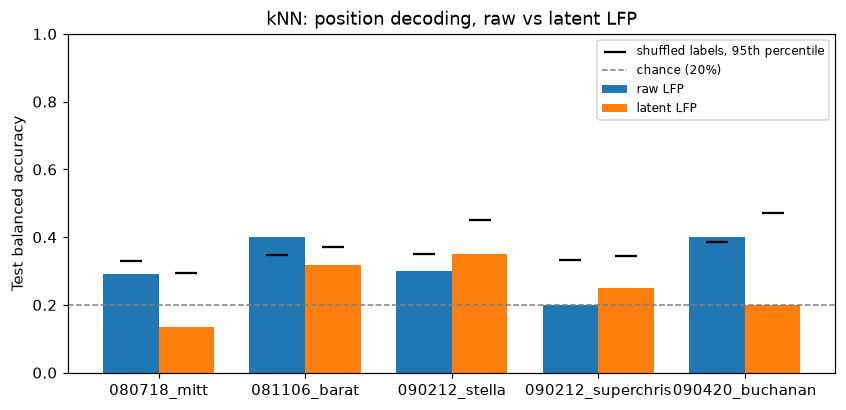

In [7]:
table = results_df.pivot(index='rat', columns='input', values='test_bal_acc')[['raw', 'latent']]
shuffle = results_df.pivot(index='rat', columns='input', values='shuffle_95th')[['raw', 'latent']]

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(table))
for i, name in enumerate(['raw', 'latent']):
    ax.bar(x + (i - .5) * .38, table[name], width=.38, label=f'{name} LFP')
    ax.scatter(x + (i - .5) * .38, shuffle[name], color='k', marker='_', s=200, zorder=3,
               label='shuffled labels, 95th percentile' if i == 0 else None)
ax.axhline(.2, color='gray', ls='--', lw=1, label='chance (20%)')
ax.set(xticks=x, xticklabels=table.index, ylim=(0, 1), ylabel='Test balanced accuracy',
       title='kNN: position decoding, raw vs latent LFP')
ax.legend(fontsize=8)
plt.show()

Confusion matrices on the test split: rows are the true position, columns the predicted position. A strong diagonal means correct predictions; a full first column means the model mostly predicts position 1.

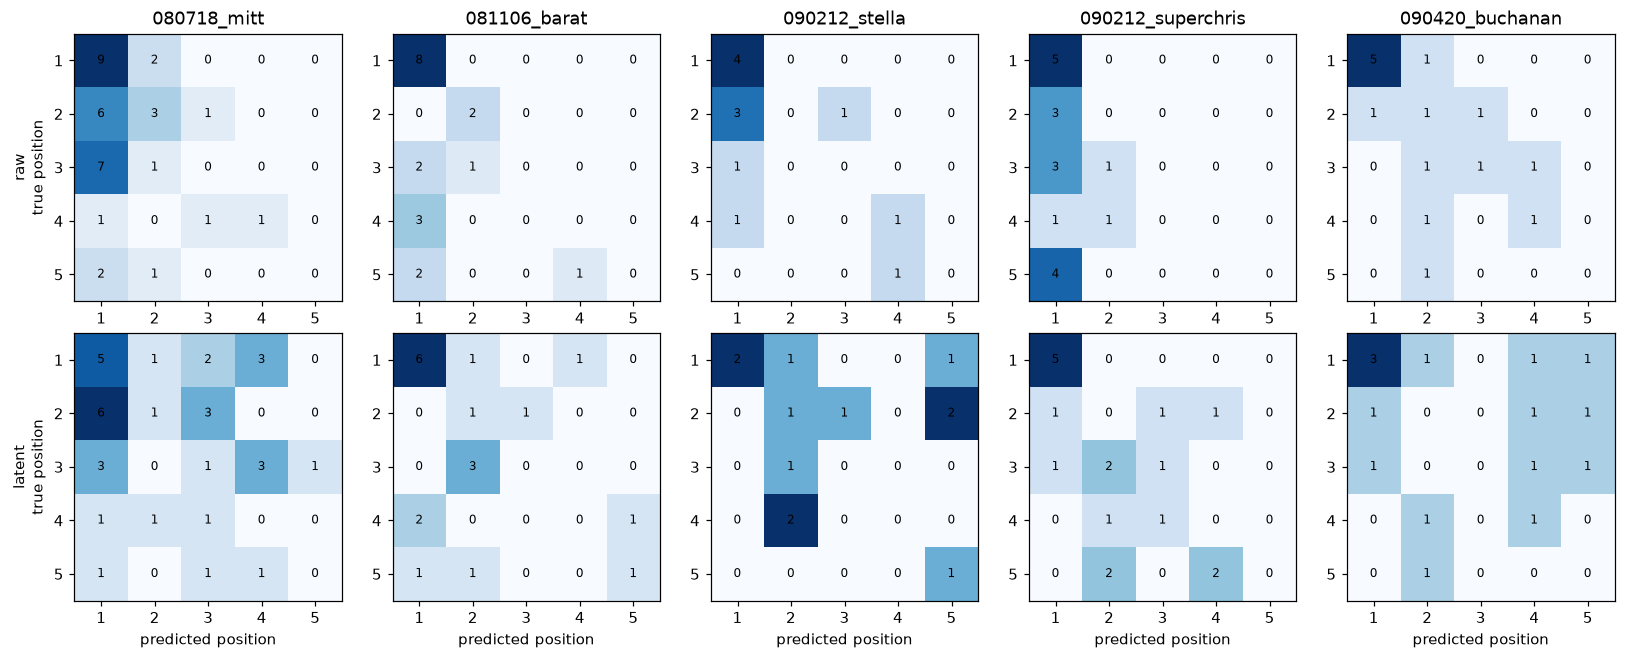

In [8]:
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(2, len(SESSIONS), figsize=(3 * len(SESSIONS), 6), squeeze=False)
for col, session in enumerate(SESSIONS):
    y_test = data[session]['y'][data[session]['split'] == 'test']
    for row, name in enumerate(['raw', 'latent']):
        pred = next(r['pred'] for r in results if r['rat'] == session and r['input'] == name)
        cm = confusion_matrix(y_test, pred, labels=range(5))
        ax = axes[row, col]
        ax.imshow(cm, cmap='Blues')
        for i in range(5):
            for j in range(5):
                ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=8)
        ax.set(xticks=range(5), xticklabels=range(1, 6), yticks=range(5), yticklabels=range(1, 6),
               title=session if row == 0 else '')
        if col == 0:
            ax.set_ylabel(f'{name}\ntrue position')
        if row == 1:
            ax.set_xlabel('predicted position')
plt.tight_layout()
plt.show()

## Summary

kNN decodes position more weakly than logistic regression, but shows the same pattern.

| Rat | Test trials | Raw | Shuffled 95th | Latent | Shuffled 95th |
|---|---|---|---|---|---|
| Mitt | 35 | 29.0% | 33.0% | 13.6% | 29.4% |
| Barat | 19 | 40.0% | 34.6% | 31.7% | 37.1% |
| Stella | 12 | 30.0% | 35.0% | 35.0% | 45.0% |
| Superchris | 18 | 20.0% | 33.3% | 25.0% | 34.5% |
| Buchanan | 15 | 40.0% | 38.5% | 20.0% | 47.0% |
| Mean ± SD | – | 31.8% ± 8.4 | – | 25.1% ± 8.7 | – |

Test balanced accuracy; chance is 20%. Logistic regression on the same data and splits: 40.7% raw, 30.2% latent.

**Raw LFP:** above the shuffled-label baseline only in Barat and Buchanan, the same two rats where logistic regression was clearly above it. Two different models agreeing makes those two results more credible.

**Latent LFP:** not above the shuffled baseline in any rat, agreeing with logistic regression that these latents carry little position information.

**Confusion matrices:** on raw LFP, kNN predicts position 1 for most trials. Mitt and Superchris chose `k = 25`, and Superchris predicts position 1 for every test trial, which gives exactly 20%.
Position-1 trials themselves are almost always correct, the same pattern seen with logistic regression. Position 1 is always odor A on InSeq trials.

**Why kNN is weaker:** it treats all ~200 features as equally important when measuring similarity, while logistic regression learns which time bins and channels matter.
If only a few features carry the signal, such as the early response after odor onset, kNN's distances are dominated by the rest.

**Caveats**
- Very small test sets (12–35 trials, some positions with 1–3).
- kNN has no class weighting, so large `k` favors position 1, the most common position in training.
- One train / validation / test split and one CEBRA seed.

**Overall:** across both models, evidence for position decoding from raw LFP is weak, mostly limited to Barat and Buchanan, and driven by position 1 and the early response to odor onset. The CEBRA latents add nothing.